In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [3]:
MAX_INTENSITY = 255.0
x_train_full = x_train_full.astype("float32") / MAX_INTENSITY
x_test = x_test.astype("float32") / MAX_INTENSITY

N_TRAIN = 50_000
x_val, y_val = x_train_full[N_TRAIN:], y_train_full[N_TRAIN:]
x_train, y_train = x_train_full[:N_TRAIN], y_train_full[:N_TRAIN]

In [4]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]


In [5]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (50000, 28, 28), val: (10000, 28, 28), test: (10000, 28, 28), class: 10


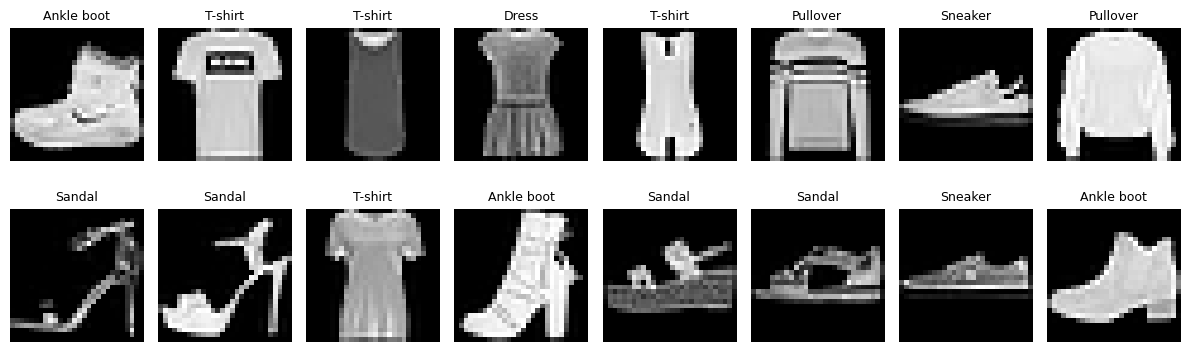

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
dense = keras.Sequential(
    [
        keras.Input(shape=(28, 28, 1)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax")
    ]
)

dense.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

dense.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
hist_dense = dense.fit(x_train, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 745us/step - accuracy: 0.8116 - loss: 0.5314 - val_accuracy: 0.8374 - val_loss: 0.4454
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 732us/step - accuracy: 0.8582 - loss: 0.3967 - val_accuracy: 0.8508 - val_loss: 0.4026
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 686us/step - accuracy: 0.8685 - loss: 0.3584 - val_accuracy: 0.8649 - val_loss: 0.3648
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 675us/step - accuracy: 0.8790 - loss: 0.3275 - val_accuracy: 0.8759 - val_loss: 0.3436
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 681us/step - accuracy: 0.8862 - loss: 0.3102 - val_accuracy: 0.8685 - val_loss: 0.3650
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 680us/step - accuracy: 0.8903 - loss: 0.2947 - val_accuracy: 0.8601 - val_loss: 0.3908
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 677us/step - accuracy: 0.8956 - loss: 0.2835 - val_accuracy: 0.8838 - val_loss: 0.3236
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 731us/step - accuracy: 0.9004 -

In [ ]:
cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 3, activation="relu"), 
    layers.MaxPooling2D(), 
    layers.Conv2D(128, 3, activation="relu"), 
    layers.MaxPooling2D(), 
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(), 
    layers.Flatten(),
    layers.Dense(10, activation="softmax") 
])


cnn.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 3, 3, 64)       │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 1, 1, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 148,938 (581.79 KB)

 Trainable params: 148,938 (581.79 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
hist_cnn = cnn.fit(x_train, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7855 - loss: 0.5980 - val_accuracy: 0.8356 - val_loss: 0.4535
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.8516 - loss: 0.4126 - val_accuracy: 0.8627 - val_loss: 0.3809
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.8695 - loss: 0.3558 - val_accuracy: 0.8684 - val_loss: 0.3565
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8854 - loss: 0.3136 - val_accuracy: 0.8731 - val_loss: 0.3476
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.8974 - loss: 0.2827 - val_accuracy: 0.8814 - val_loss: 0.3300
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9046 - loss: 0.2585 - val_accuracy: 0.8883 - val_loss: 0.3084
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9142 - loss: 0.2341 - val_accuracy: 0.8912 - val_loss: 0.3060
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9198 - loss: 0.2141 - 

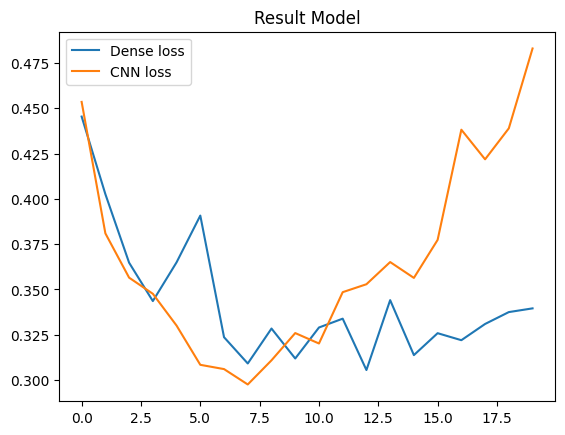

In [16]:
plt.plot(hist_dense.history["val_loss"], label="Dense loss")
plt.plot(hist_cnn.history["val_loss"], label="CNN loss")
plt.title("Result Model")
plt.legend()
plt.show()